# EV battery current — from data to insight

**Python for Engineers · Term Project**  
Türk-Alman Üniversitesi, Winter 2026 · Dr. Berfin Aktaş  
Can Keçilioğlu

> Can the **signed** battery current of an electric vehicle (`CUR`, in A) be
> estimated from simultaneous driving signals — speed and acceleration, pedal
> inputs, and the ECO / air-conditioning states — including regenerative braking?

This notebook is the narrative of the project. It loads and cleans the raw
telemetry, shows what the data actually contain, calibrates a longitudinal
power balance, trains a Random Forest, compares both against a mean baseline on
a time-ordered test set, and analyses where the errors come from. The reusable
logic lives in `src/`; the notebook calls it so that the numbers here and the
CLI results cannot drift apart.

**Contents**

1. Setup
2. Loading and cleaning
3. Is the target really signed?
4. What the data look like
5. Feature engineering: why not use `AX`?
6. Time-ordered split
7. Physics-based calibration
8. Random Forest and model comparison
9. Per-driver robustness check
10. Error analysis
11. ECO mode: a confounded natural experiment
12. Conclusions and limitations


## 1. Setup

Run this notebook from the repository root, with the virtual environment that
has `requirements.txt` installed. The raw file must be at `data/raw/dataset.csv`
(download link and licence in README §2).

All figures are saved under `results/figures` and displayed from disk, so the
notebook works with the same headless plotting backend as the CLI.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from src import config, diagnostics, exploration, modeling, quality
from src.cleaning import add_elapsed_time, clean_telemetry
from src.features import MODEL_FEATURES, build_features
from src.io import load_raw_data
from src.plotting import apply_style

apply_style()
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

DATA_PATH = Path("data/raw/dataset.csv")
assert DATA_PATH.exists(), (
    "dataset.csv is missing: download it from Kaggle into data/raw/ "
    "(link and licence in README section 2)"
)

import matplotlib
import numpy
import sklearn

print(
    "pandas", pd.__version__,
    "| numpy", numpy.__version__,
    "| scikit-learn", sklearn.__version__,
    "| matplotlib", matplotlib.__version__,
)

pandas 3.1.0 | numpy 2.4.6 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 2. Loading and cleaning

The file is **not** stored in time order: rows from the nine trips are
interleaved. The cleaning pipeline therefore rebuilds the UTC timestamp from
the Y/M/D/H/MIN/SEC components, sorts per trip, validates the components
explicitly (pandas silently rolls hour 83 into a later day), flags sentinel
values instead of deleting them, and removes only rows whose time or physical
range cannot be trusted.

The quality table below is produced by `src/quality.py` and is the same table
written to `results/tables/data_quality_report.md`.


In [2]:
raw = load_raw_data(DATA_PATH)
clean, report = clean_telemetry(raw)
clean = add_elapsed_time(clean)

print(f"raw rows    : {report.n_raw:,}")
print(f"dropped     : {report.n_raw - report.n_clean:,} rows ({report.removed_pct:.2f} %)")
print(f"usable rows : {report.n_clean:,}")

quality.build_quality_table(report)

raw rows    : 24,277
dropped     : 97 rows (0.40 %)
usable rows : 24,180


,Issue,Count,Decision
0,Raw rows read,24277,Starting point of the pipeline.
1,Unparseable UTC timestamp,69,Y/M/D/H/MIN/SEC contained impossible component...
2,Timestamp outside 2023,2,Two-digit year 0 (-> 2000) or corrupted date. ...
3,"Duplicate (trip, timestamp)",0,Same trip recorded twice at the same second; f...
4,Timestamp inconsistent with recording order,26,"id order is 100 % monotonic with the odometer,..."
5,Physically impossible values,0,"Speed outside 0-200 km/h, pedals outside 0-100..."
6,Missing cells in raw file,0,The file has no NaN cells; missing data is enc...
7,ALT == 0 (missing altitude),4,"Route is driven between 850 and 1350 m, so 0 m..."
8,VOL outside 250-420 V,18049,The pack-voltage channel is corrupted on 7 of ...
9,GPS outside Brazil bounding box,21,Sign bit lost / zeroed fixes. Flagged (gps_val...


Two decisions are worth remembering:

- **Rows with impossible timestamps are dropped, not repaired.** 69 timestamps
  contain impossible components (month 49, hour 83, …) and 28 more are
  impossible or contradict the recording order. There is no honest way to know
  when those observations were made.
- **Corrupt channels are flagged, not deleted.** The pack voltage is outside
  250–420 V on 18,049 rows (7 of 9 trips), altitude is 0 on 4 rows, and 21 GPS
  fixes fall outside Brazil. Deleting those rows would throw away valid speed,
  pedal and current measurements, so the pipeline keeps them and records
  `vol_valid`, `alt_missing` and `gps_valid` flags.


In [3]:
display(report.gap_summary)
display(quality.build_trip_table(clean))

,COND,n_rows,start_utc,end_utc,median_dt_s,n_gaps,largest_gap_s,total_gap_s
0,1,2942,2023-10-23 17:17:10+00:00,2023-10-23 18:36:15+00:00,2.0,0,0.0,0.0
1,2,2653,2023-10-24 00:27:35+00:00,2023-10-24 01:39:15+00:00,2.0,0,0.0,0.0
2,3,2634,2023-10-24 11:55:57+00:00,2023-10-24 13:07:24+00:00,2.0,0,0.0,0.0
3,4,2992,2023-10-24 14:20:22+00:00,2023-10-24 15:40:16+00:00,2.0,0,0.0,0.0
4,5,2825,2023-10-24 17:22:44+00:00,2023-10-24 18:37:51+00:00,2.0,0,0.0,0.0
5,6,3211,2023-10-24 21:59:46+00:00,2023-10-24 23:25:40+00:00,2.0,0,0.0,0.0
6,7,3144,2023-10-26 16:56:09+00:00,2023-10-26 18:20:57+00:00,2.0,0,0.0,0.0
7,8,2987,2023-10-26 18:48:56+00:00,2023-10-26 20:14:12+00:00,2.0,1,322.0,322.0
8,9,792,2023-10-23 12:54:22+00:00,2023-10-23 14:30:44+00:00,2.0,1,4507.0,4507.0


,COND,rows,start_utc,end_utc,duration_min,median_dt_s,distance_km
0,1,2942,2023-10-23 17:17:10+00:00,2023-10-23 18:36:15+00:00,79.1,2.0,76.4
1,2,2653,2023-10-24 00:27:35+00:00,2023-10-24 01:39:15+00:00,71.7,2.0,75.8
2,3,2634,2023-10-24 11:55:57+00:00,2023-10-24 13:07:24+00:00,71.5,2.0,76.3
3,4,2992,2023-10-24 14:20:22+00:00,2023-10-24 15:40:16+00:00,79.9,2.0,76.0
4,5,2825,2023-10-24 17:22:44+00:00,2023-10-24 18:37:51+00:00,75.1,2.0,68.9
5,6,3211,2023-10-24 21:59:46+00:00,2023-10-24 23:25:40+00:00,85.9,2.0,76.0
6,7,3144,2023-10-26 16:56:09+00:00,2023-10-26 18:20:57+00:00,84.8,2.0,76.2
7,8,2987,2023-10-26 18:48:56+00:00,2023-10-26 20:14:12+00:00,85.3,2.0,76.2
8,9,792,2023-10-23 12:54:22+00:00,2023-10-23 14:30:44+00:00,96.4,2.0,88.4


Trip 9 is the only serious transmission loss (one 75-minute hole: 88 km on
the odometer but 792 samples). Gaps are reported and drawn as breaks in the
time-series figures; they are never interpolated.


## 3. Is the target really signed?

The project estimates **one signed current**: positive = drawn from the pack,
negative = energy flowing back during regenerative braking. Before modelling,
the sign convention is checked against the pedals.


In [4]:
sign_convention = pd.Series(
    {
        "rows with CUR < 0 (regenerating)": int((clean["CUR"] < 0).sum()),
        "CUR < 0 while braking (BRK > 0)": int(((clean["CUR"] < 0) & (clean["BRK"] > 0)).sum()),
        "CUR < 0 while coasting (no pedal)": int(
            ((clean["CUR"] < 0) & (clean["ACC"] == 0) & (clean["BRK"] == 0)).sum()
        ),
        "CUR > 0 while braking (hydraulics first)": int(
            ((clean["CUR"] > 0) & (clean["BRK"] > 0)).sum()
        ),
        "CUR range [A]": f"{clean['CUR'].min():.0f} ... {clean['CUR'].max():.0f}",
    },
    name="value",
)
sign_convention.to_frame()

,value
rows with CUR < 0 (regenerating),6596
CUR < 0 while braking (BRK > 0),1486
CUR < 0 while coasting (no pedal),4735
CUR > 0 while braking (hydraulics first),1375
CUR range [A],-52 ... 301


Roughly a quarter of the samples are negative, both while braking and while
coasting — exactly the signature of lift-off recuperation. A few negative
samples coincide with a pressed accelerator (sensor noise or torque blending
during a mode change); they are kept, because they are real sensor output, and
discussed in the error analysis rather than deleted.


## 4. What the data look like

**Figure 1** — one trip, four channels. The line is broken where samples are
missing; it is never bridged with a straight line, because that would draw
driving that was never recorded.

**Figure 2** — pack voltage per trip. Only trips 7 and 8 carry a plausible
300–380 V signal; the other seven sit near 0–25 V, which is why the models
predict current and use the nominal 350 V in the physics term.


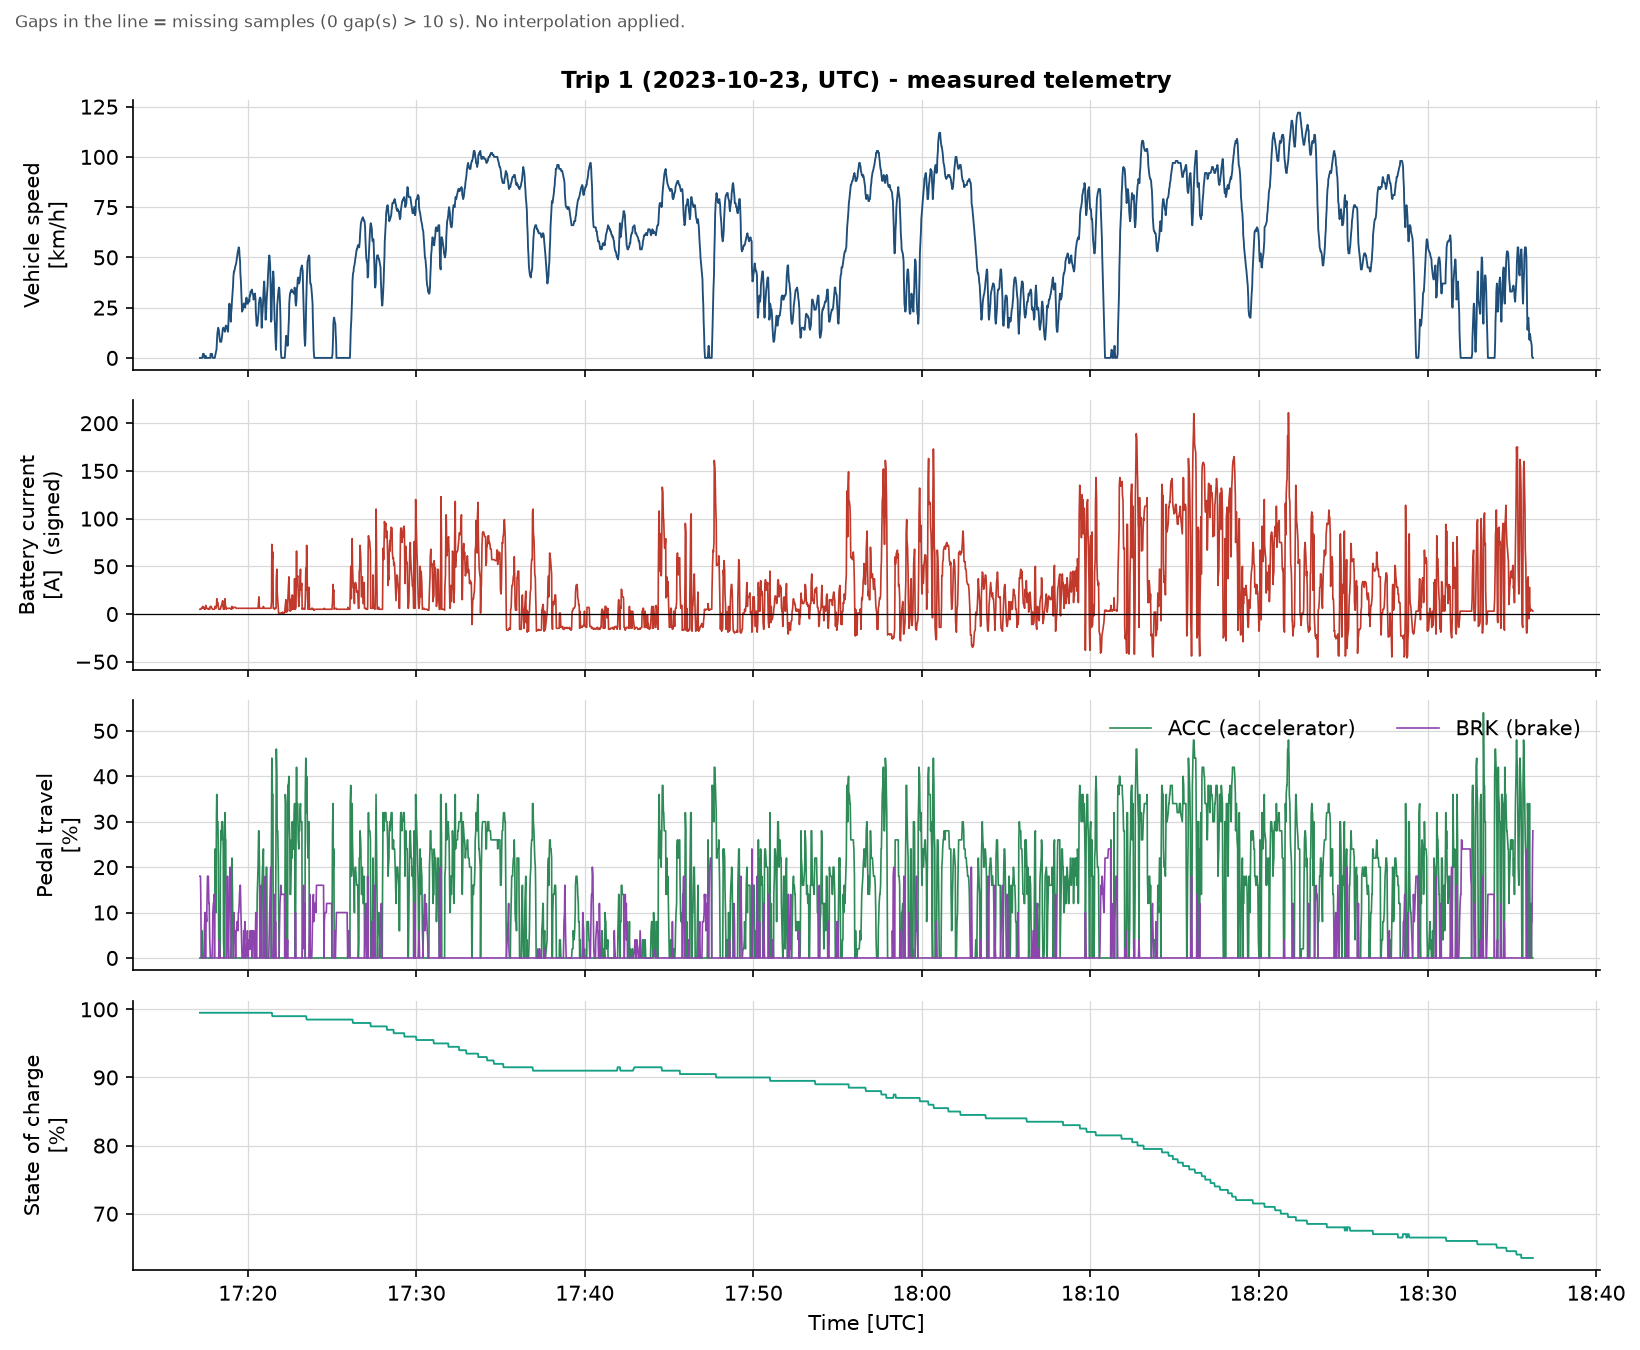

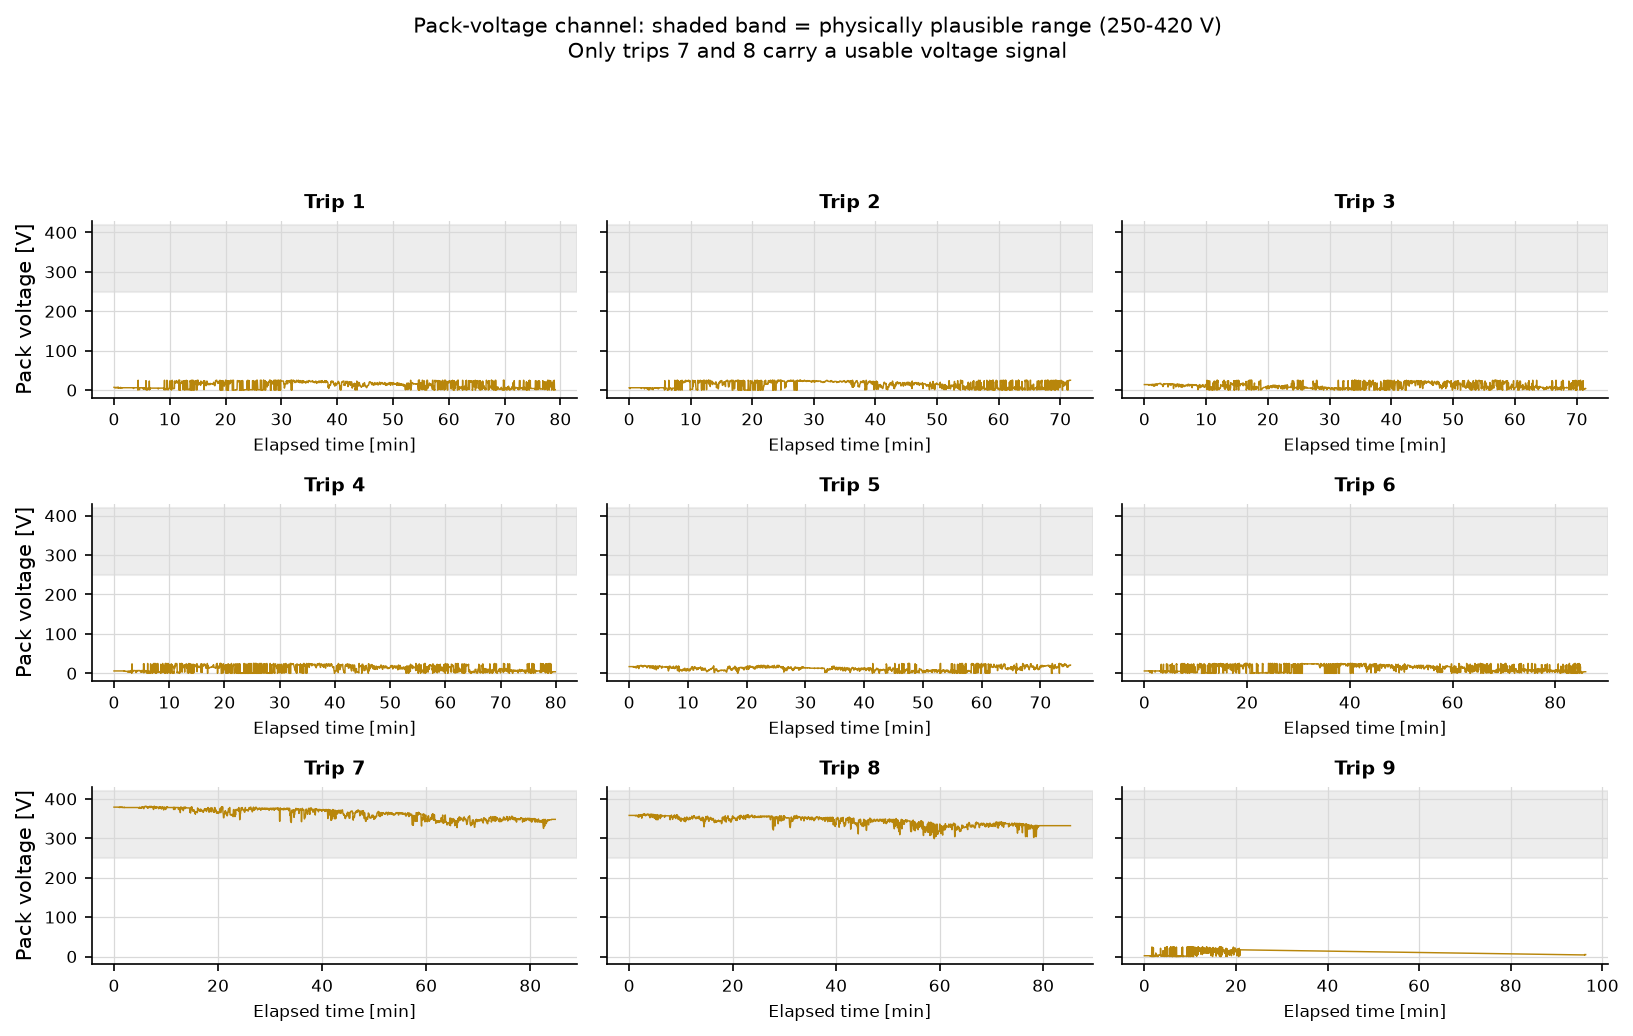

In [5]:
figures = [
    exploration.plot_trip_timeseries(clean, trip=1),
    exploration.plot_voltage_channel(clean),
]
for path in figures:
    display(Image(filename=str(path), width=950))

**Figure 3** — current versus pedal travel over all nine trips. The
accelerator explains most of the current variation (r ≈ +0.91). The brake panel
is mostly empty at zero travel, which is the normal state of a brake pedal;
when it is pressed, current is often negative (regeneration) or still positive
(hydraulics before regen engages).

This single figure also explains why the Random Forest will be much better
than the physics model later: the pedal-to-current map of this particular
vehicle is a very strong, simultaneous signal.


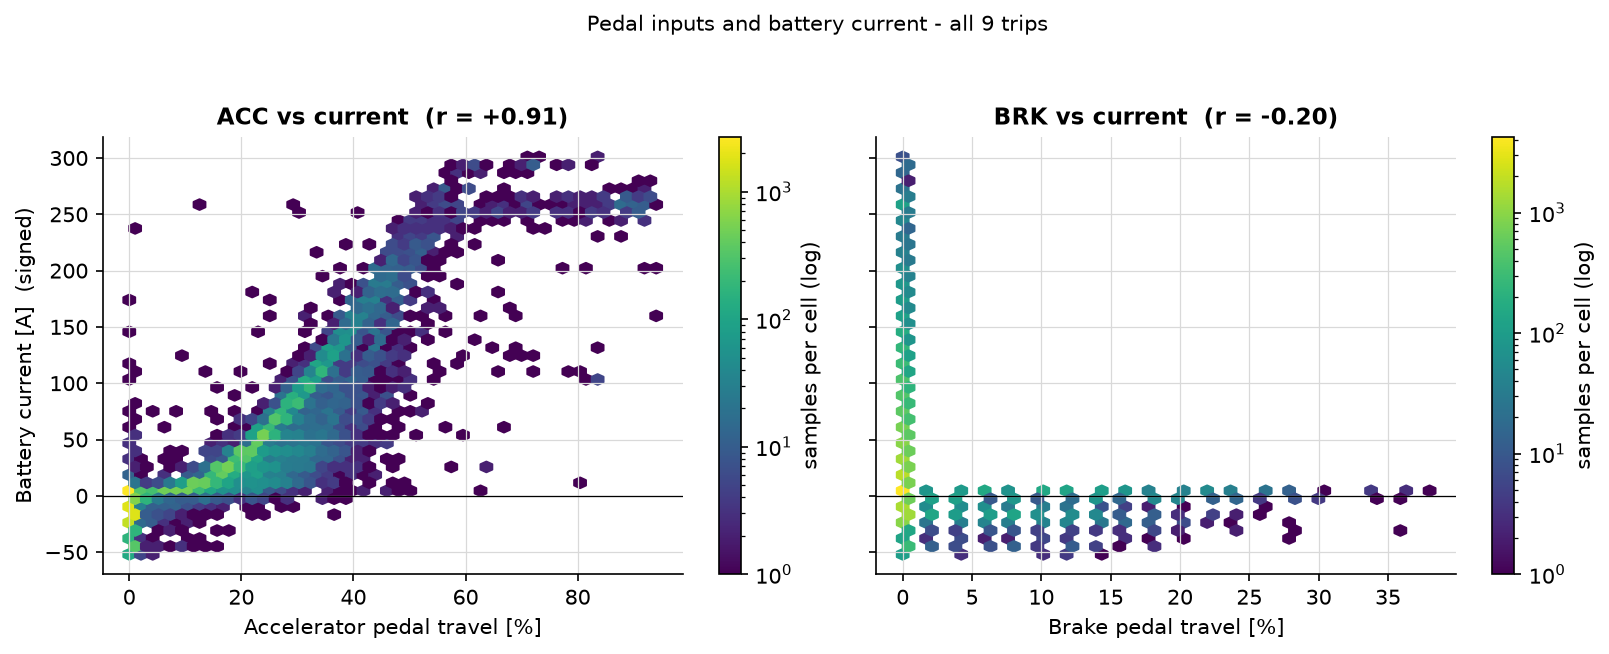

In [6]:
display(Image(filename=str(exploration.plot_pedal_response(clean)), width=950))

## 5. Feature engineering: why not use `AX`?

The dataset contains a three-axis accelerometer, but its longitudinal axis is
**not** usable as acceleration. It has a per-trip offset (the sensor is mounted
with a small pitch/roll and never re-zeroed) and correlates poorly with the
differentiated speed. The table below quantifies it on the cleaned data.

The pipeline therefore uses `a = dSPD/dt` per trip. The first sample of each
trip has no predecessor and stays `NaN`; the imputer handles it inside the
training pipeline, never across the split.


In [7]:
features = build_features(clean)

correlation = pd.DataFrame(
    {
        "correlation with CUR": [
            features["AX"].corr(features["CUR"]),
            features["accel_mps2"].corr(features["CUR"]),
        ],
        "correlation with dSPD/dt": [
            features["AX"].corr(features["accel_mps2"]),
            1.0,
        ],
    },
    index=["AX accelerometer", "dSPD/dt (used)"],
)
display(correlation.round(3))

ax_offset = (
    features.groupby(config.GROUP_COL)["AX_mps2"]
    .median()
    .rename("median AX per trip [m/s^2]")
    .to_frame()
)
display(ax_offset.round(2))

print("model features:", MODEL_FEATURES)

,correlation with CUR,correlation with dSPD/dt
AX accelerometer,0.215,0.144
dSPD/dt (used),0.496,1.000


,median AX per trip [m/s^2]
COND,
1,0.39
2,1.40
3,3.13
4,0.42
5,0.11
6,-0.12
7,0.66
8,0.07
9,0.45


model features: ['SPD', 'accel_mps2', 'ACC', 'BRK', 'ECO_bin', 'AIR_bin', 'grade_pct']


The accelerometer correlates with current at only r ≈ 0.22, while the
differentiated speed reaches r ≈ 0.50. Per-trip median offsets lie between
−0.1 and +3.1 m/s² (0.07–3.13 in magnitude) — far larger than the accelerations that matter for the power
balance. This is a **sensor-quality finding**, not a modelling convenience, and
it is documented in README §5.


## 6. Time-ordered split

The split is chronological: rows sorted by timestamp, the first 80 % for
training and the last 20 % for testing. Nothing is shuffled. The cut falls on
26 October 2023, so the test set contains the end of trip 7 and all of trip 8 —
**unseen drivers and a new day**, which is the honest question for a deployment.

The gap between training and test rows below is expected: trip 9 was recorded
earlier (23 October) and therefore belongs entirely to training.


In [8]:
split = modeling.chronological_split(features, test_fraction=config.TEST_FRACTION)
print(
    f"train {len(split.train):,} rows | test {len(split.test):,} rows "
    f"| cut at {split.split_timestamp}"
)
modeling.split_composition(split)

train 19,344 rows | test 4,836 rows | cut at 2023-10-26 17:31:09+00:00


,COND,train_rows,test_rows
0,1,2942,0
1,2,2653,0
2,3,2634,0
3,4,2992,0
4,5,2825,0
5,6,3211,0
6,7,1295,1849
7,8,0,2987
8,9,792,0
9,total,19344,4836


## 7. Physics-based calibration

The reference model is a longitudinal power balance evaluated at the pack:

$$
I_{batt} = \frac{m\,a\,v + \tfrac12 \rho C_d A\,v^3
                 + m g \sin\theta\,v + C_{rr} m g \cos\theta\,v}{\eta\,V_{nom}}
           + \frac{P_{base} + P_{air}\cdot\mathbb{1}_{AIR}}{V_{nom}}
$$

With $\cos\theta \approx 1$ (below 1 % error at the 15 % grade clip) the
equation is linear in six coefficients: `m/η`, `½ρC_dA/η`, `m·g/η`,
`C_rr·m·g/η`, `P_base` and `P_air`. It is fitted by ordinary least squares on
**training rows only**, and the coefficients are translated back into apparent
mass, `C_dA` and `C_rr` for a physical sanity check.

Assumptions: quasi-steady motion, no wheel slip, one efficiency for traction
and regeneration, auxiliary load independent of speed, grade from 1 m-resolution
altitude over a trailing ~30 s window, and nominal pack voltage 350 V because
the measured voltage is corrupt on seven trips.


In [9]:
calibration = modeling.fit_physics_calibration(split.train)
print(f"fitted on {calibration.n_fit_rows:,} training rows")
calibration.interpretation()

fitted on 18,035 training rows


,Coefficient,Fitted,Prior,Meaning,Implied
0,m / eta [kg],969.797399,1705.555556,apparent mass,873 kg
1,rho*Cd*A / (2 eta),0.611504,0.460800,aerodynamic drag,CdA = 0.917 m^2
2,m*g / eta [N],10452.578001,16725.786389,grade force,959 kg
3,Crr*m*g / eta [N],90.438392,200.709437,rolling resistance,Crr = 0.0095
4,P_base [W],3066.562620,NaN,base electrical load,
5,P_air [W],1147.754655,NaN,air-conditioning load,


How to read this table:

- The **traction mass (873 kg) and the grade mass (959 kg)** come from two
  independent coefficients and agree within 10 %. That internal consistency is
  the strongest evidence that the fitted equation is physically coherent.
- Both are ~40 % below the published 1,535 kg kerb mass. The most plausible
  reasons are that `dSPD/dt` over 2 s smooths short acceleration peaks and that
  a single efficiency cannot represent traction and regeneration at the same
  time. The coefficient table is reported unchanged; this is a discussion
  point, not a hidden correction.
- `C_rr = 0.0095` is close to the 0.012 prior, `C_dA = 0.917 m²` is higher than
  the 0.69 m² prior, and the auxiliary load is about 3.1 kW base + 1.1 kW with
  air conditioning — plausible for a compact EV.


## 8. Random Forest and model comparison

The forest sees only information available **at the same instant**: speed,
differentiated acceleration, both pedals, the ECO and air-conditioning flags,
and road grade. It is tuned with `TimeSeriesSplit(5)` **inside the training
set**; no test row ever influences the imputer or the hyper-parameters.

The optional linear regression on speed and acceleration is included as the
simple reference the instructor allowed.


In [10]:
metrics, predictions, extras = modeling.evaluate_models(split, tune_rf=True)
metrics

,method,key,features,MAE_A,RMSE_A,bias_A,R2,n_test
0,training mean,baseline,-,40.348,54.581,-2.835,-0.0027,4836
1,linear regression,linear,"SPD, acceleration",31.958,43.942,-2.624,0.3501,4836
2,physics calibration,physics,"a*v, v^3, grade, v, AIR",25.028,36.054,-0.468,0.5625,4836
3,random forest,rf,"SPD, accel_mps2, ACC, BRK, ECO_bin, AIR_bin, g...",5.425,9.433,-0.466,0.9700,4836


In [11]:
print(f"cross-validated MAE inside training: {extras['rf_cv_mae']:.2f} A")
print("selected parameters:", extras["rf_params"])

importance = pd.Series(extras["rf_importances"]).sort_values(ascending=False)
importance.to_frame("feature importance")

cross-validated MAE inside training: 6.96 A
selected parameters: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 200}


,feature importance
ACC,0.8968
SPD,0.0696
accel_mps2,0.0150
ECO_bin,0.0131
grade_pct,0.0039
AIR_bin,0.0012
BRK,0.0003


The forest reaches **≈ 5.4 A MAE**, against 25 A for the calibrated physics
model, 32 A for the linear reference and 40 A for the mean baseline.

The feature-importance table explains the gap: 90 % of the forest's decisions
come from the accelerator pedal, then speed (7 %) and acceleration (1.5 %).
The forest is, to a large extent, a learned pedal-to-current map of **this**
vehicle. That is a legitimate simultaneous signal and a useful result — but it
also means the physics model is the one that would transfer to another EV,
while the forest is tied to this pedal calibration.


## 9. Per-driver robustness check

The global chronological split puts only two drivers in the test set. As a
secondary check, the last 20 % of **every** trip is held out, so all nine
drivers appear in the test set. The Random Forest is not re-tuned here
(`tune_rf=False`), so this is a fair out-of-the-box comparison.


In [12]:
per_trip = modeling.per_trip_split(features, test_fraction=config.TEST_FRACTION)
metrics_pt, _, _ = modeling.evaluate_models(per_trip, tune_rf=False)
metrics_pt[["method", "MAE_A", "bias_A", "n_test"]]

,method,MAE_A,bias_A,n_test
0,training mean,38.479,-2.663,4835
1,linear regression,33.200,-1.571,4835
2,physics calibration,27.239,0.542,4835
3,random forest,6.208,-0.681,4835


The ranking is unchanged (forest ≈ 6.2 A, physics ≈ 27 A, linear ≈ 33 A,
baseline ≈ 38 A), so the conclusion is not an artefact of which trips happen to
fall after the global cut.


## 10. Error analysis

Where do the models fail? The tables split the same test predictions by speed
band, road grade and pedal regime. `src/modeling.py` builds the bands once, so
every method is compared on **identical rows**.


In [13]:
methods = ("baseline", "linear", "physics", "rf")
analysed = modeling.add_operating_regime(predictions)

error_speed = modeling.error_table(analysed, "speed_band", methods)
error_regime = modeling.error_table(analysed, "regime", methods)
error_grade = modeling.error_table(analysed, "grade_band", methods)

display(error_regime.pivot(index="regime", columns="method", values="MAE_A").round(1))
display(error_speed.pivot(index="speed_band", columns="method", values="MAE_A").round(1))
display(error_grade.pivot(index="grade_band", columns="method", values="MAE_A").round(1))

method,baseline,linear,physics,rf
regime,,,,
accelerating,39.4,31.0,25.8,5.3
braking,38.8,24.3,14.6,3.9
coasting,43.7,38.0,26.9,6.5


method,baseline,linear,physics,rf
speed_band,,,,
0-20,24.2,17.5,9.4,2.6
20-40,29.8,21.8,17.0,4.2
40-60,34.1,24.8,19.7,4.9
60-80,41.7,34.4,26.8,6.7
80-100,61.0,50.8,38.9,7.4
100+,53.4,46.0,45.3,6.9


method,baseline,linear,physics,rf
grade_band,,,,
downhill,38.3,33.0,21.4,5.5
flat,36.4,29.4,26.1,5.1
uphill,49.7,38.1,28.8,6.5


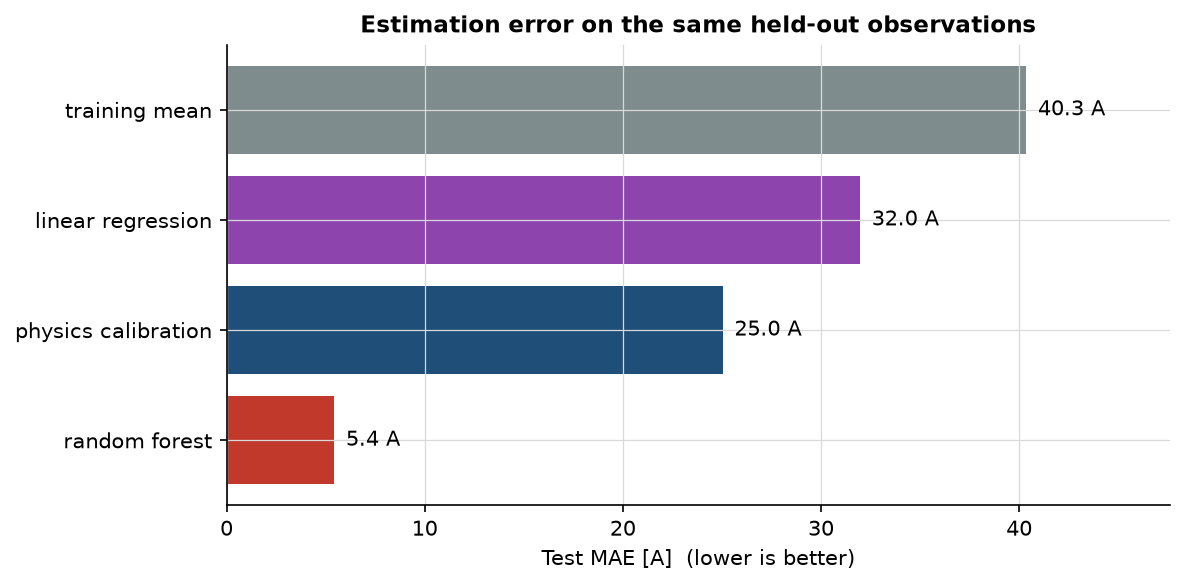

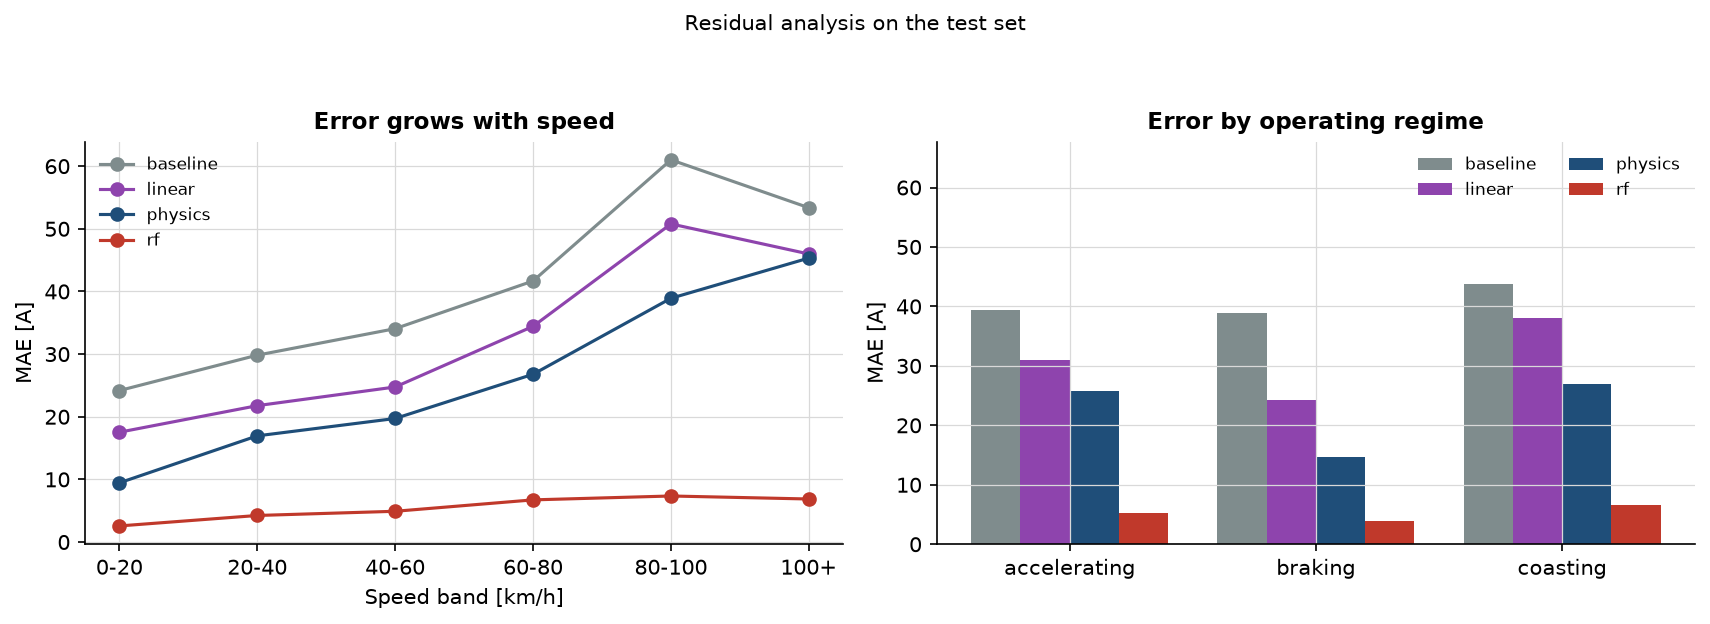

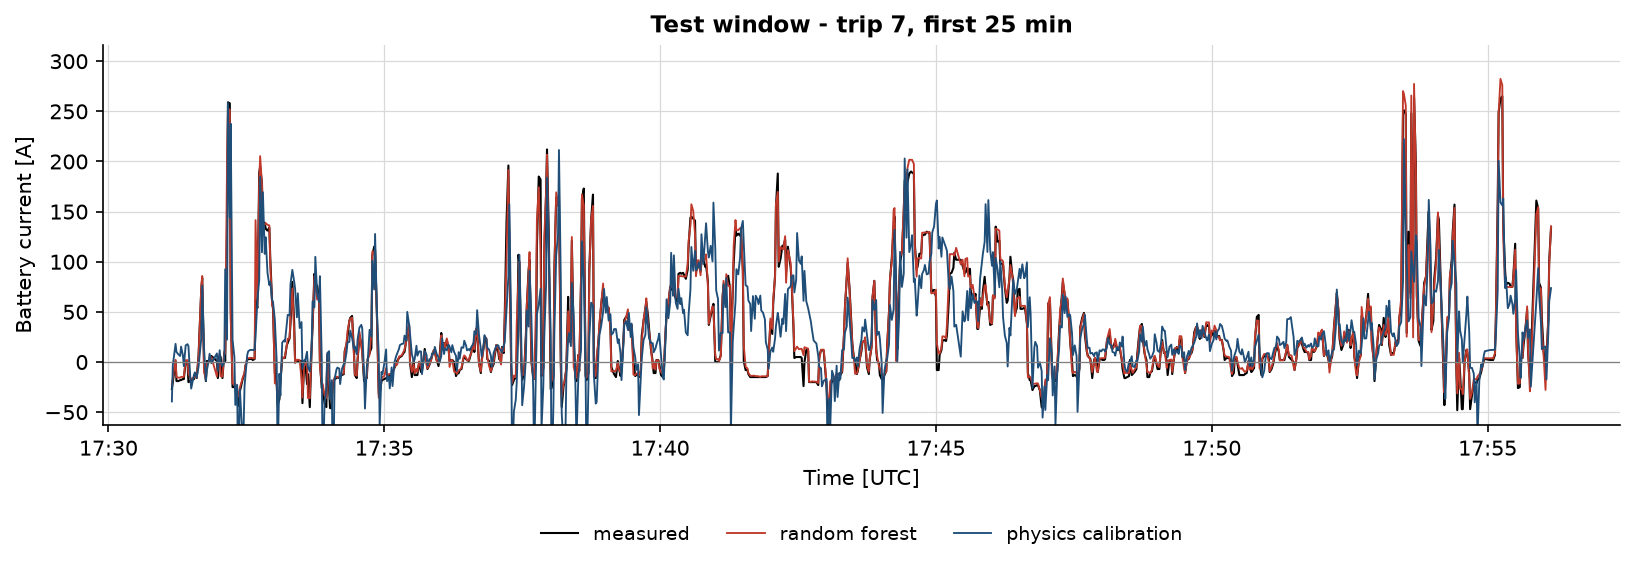

In [14]:
figures = [
    diagnostics.plot_model_comparison(metrics),
    diagnostics.plot_error_analysis(error_speed, error_regime),
    diagnostics.plot_prediction_window(
        predictions, trip=int(predictions[config.GROUP_COL].iloc[0]), minutes=25
    ),
]
for path in figures:
    display(Image(filename=str(path), width=950))

Readings:

- The **mean baseline has a large negative bias** above 80 km/h (−36 A) and
  uphill (−29 A): it is dominated by low-demand samples and cannot follow
  demand.
- The **physics model** is worst at high speed (39–45 A) and best while braking
  (15 A), because the recovery term is proportional to speed and dominates the
  balance there. Its bias stays within ±10 A, so most of the error is
  dispersion, not a systematic offset.
- The **forest** stays between 2.6 and 7.4 A in every speed band and between
  3.9 A (braking) and 6.5 A (coasting) per regime. Its largest remaining bias is
  about −3.5 A at 80–100 km/h.
- **Figure 7** compares measured, forest and physics traces over the first
  25 minutes of the test trip. The forest follows the pedal-driven spikes; the
  physics model follows the low-frequency envelope but misses transients — the
  expected signature of a quasi-steady power balance sampled every 2 s.


## 11. ECO mode: a confounded natural experiment

Trip 4 switches ECO mode on and off four times. At first sight this is a clean
within-driver experiment — same car, same route, same driver. It is not:
the ECO-on windows also contain **twice the accelerator pedal** (27 % vs 12 %)
and sit on slightly **uphill** sections (+2.2 % vs −1.2 % grade). The raw
current is therefore *higher* with ECO on (49.5 A vs 19.7 A).

The honest comparison holds speed and pedal travel fixed: samples are grouped
into speed bands and accelerator-pedal quintiles, and only cells containing
both ECO states contribute. Figure 4 shows the result, and the table below
prints the numbers behind the right panel.


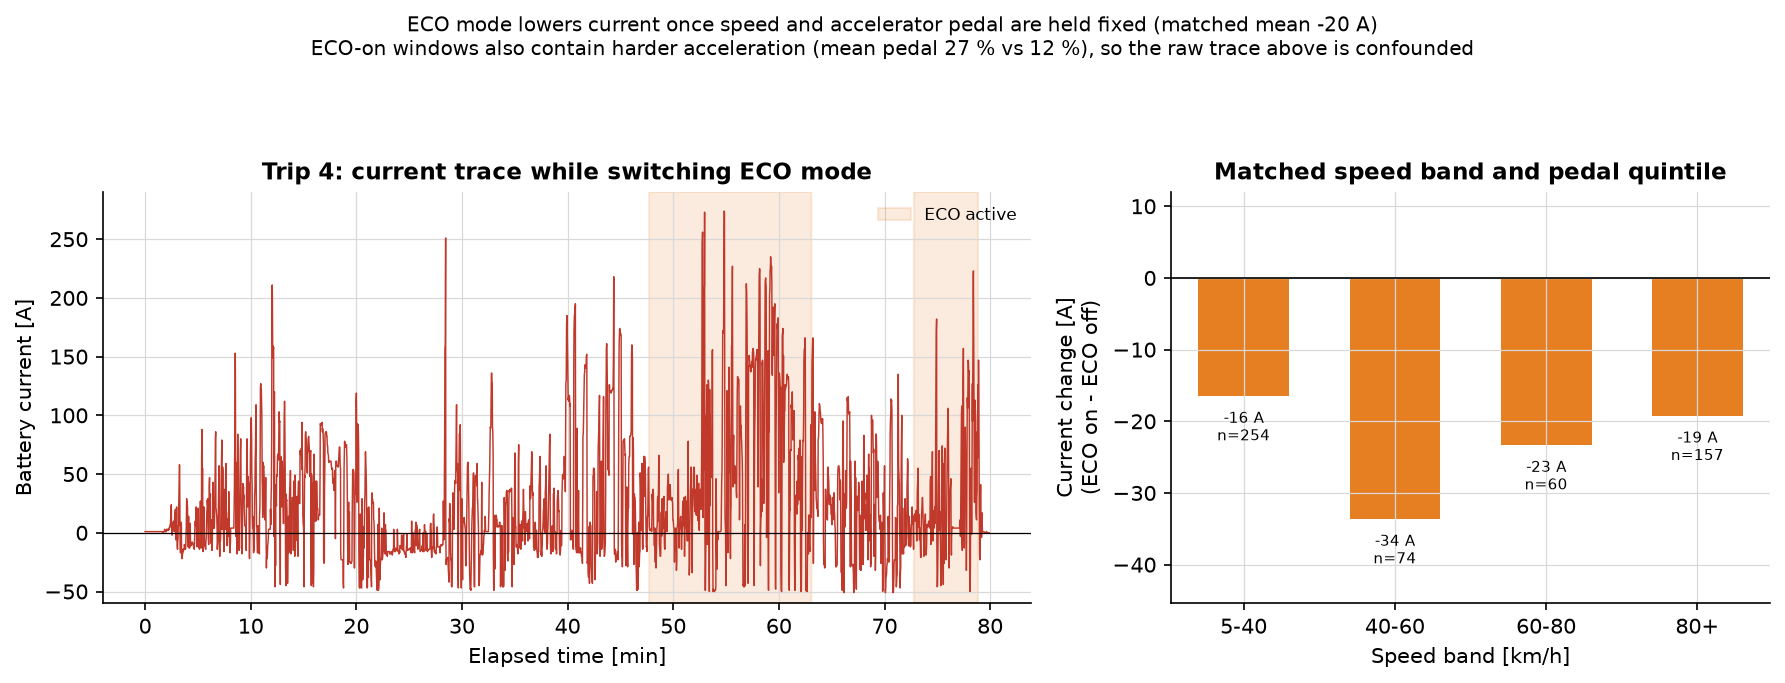

,band,delta,n
0,5-40,-16.5,254
1,40-60,-33.6,74
2,60-80,-23.3,60
3,80+,-19.2,157


Matched overall effect (ECO on - ECO off): -20.3 A


,ECO off,ECO on
current [A],19.7,49.5
accelerator pedal [%],12.0,27.1
road grade [%],-1.2,2.2


In [15]:
display(Image(filename=str(exploration.plot_eco_regime(clean, trip=4)), width=950))

matched, overall = exploration.matched_eco_summary(clean, trip=4)
display(matched.round(1))
print(f"Matched overall effect (ECO on - ECO off): {overall:+.1f} A")

trip4 = features.loc[features[config.GROUP_COL] == 4]
raw_view = pd.DataFrame(
    {
        "ECO off": [
            trip4.loc[trip4["ECO_bin"] == 0, "CUR"].mean(),
            trip4.loc[trip4["ECO_bin"] == 0, "ACC"].mean(),
            trip4.loc[trip4["ECO_bin"] == 0, "grade_pct"].mean(),
        ],
        "ECO on": [
            trip4.loc[trip4["ECO_bin"] == 1, "CUR"].mean(),
            trip4.loc[trip4["ECO_bin"] == 1, "ACC"].mean(),
            trip4.loc[trip4["ECO_bin"] == 1, "grade_pct"].mean(),
        ],
    },
    index=["current [A]", "accelerator pedal [%]", "road grade [%]"],
)
display(raw_view.round(1))

Once speed and pedal are held fixed, ECO-on current is **16–34 A lower** in
every speed band, with a matched average of about −20 A (a regression-adjusted
estimate that also controls for grade gives ≈ −15 A). The raw +30 A difference
is confounding, not physics.

Both views are kept in the report on purpose: the contrast is the finding, and
it is a good example of why an observational comparison needs matching.


## 12. Conclusions and limitations

**What was shown**

- A complete, reproducible pipeline from a shuffled raw CSV to a validated
  estimate, with the data-quality decisions written down and unit-tested.
- A calibrated longitudinal power balance whose two independent mass estimates
  agree within 10 %, and a Random Forest that reaches **5.4 A MAE** on unseen
  drivers and an unseen day, against 40 A for the mean baseline.
- Error analysis by speed, grade and regime, plus a per-driver robustness check
  that preserves the ranking.
- A re-analysis of the ECO mode that separates the mode effect from driver
  demand — the mode does lower current, but not by the raw amount.

**Limitations and honest caveats**

- The test set is small in *driver* terms (two drivers, one day in the global
  split). The per-trip check mitigates but does not remove this.
- The forest's accuracy relies on the accelerator-pedal calibration of this
  vehicle; it is not a transferable physical model.
- The physics mass is 43 % below the kerb mass, and the single efficiency
  cannot describe traction and regeneration simultaneously. Separate
  charge/discharge efficiencies and a shorter acceleration window are the
  natural next steps.
- `AX` is unusable and `VOL` is corrupt on seven trips; both are documented
  rather than silently repaired.
- The dataset is GPL-3.0 and is not redistributed with the repository.

**Where things live**

| Path | Content |
| --- | --- |
| `src/` | cleaning, features, models, figures, reporting |
| `results/figures/` | fig01 … fig07 |
| `results/tables/` | data-quality report, model comparison, coefficients, error tables |
| `tests/` | 28 unit tests (`pytest -q`) |
| `README.md` | dataset, sign convention, equation, validation protocol, results |

Reproduce everything with:

```bash
python main.py --data data/raw/dataset.csv
pytest -q
```


In [16]:
generated = sorted(config.FIGURE_DIR.glob("*.png")) + sorted(config.TABLE_DIR.glob("*.md"))
pd.Series(
    [path.relative_to(config.PROJECT_ROOT).as_posix() for path in generated],
    name="generated file",
).to_frame()

,generated file
0,results/figures/fig01_timeseries_cond01.png
1,results/figures/fig02_voltage_channel_quality.png
2,results/figures/fig03_pedal_response.png
3,results/figures/fig04_eco_regime.png
4,results/figures/fig05_model_comparison.png
5,results/figures/fig06_error_analysis.png
6,results/figures/fig07_prediction_window.png
7,results/tables/baseline_metrics.md
8,results/tables/data_quality_report.md
9,results/tables/error_by_grade.md
